In [66]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries loaded successfully")

Libraries loaded successfully


In [67]:
# Load Dataset 1
df = pd.read_csv('/content/sample_data/Dataset1_Premier_League_1993_2024.csv')

# Display basic information
print("Shape of dataset:", df.shape)
print("\nFirst 5 rows:")
df.head()

Shape of dataset: (12153, 25)

First 5 rows:


,Date,Season,HomeTeam,AwayTeam,FTH Goals,FTA Goals,FT Result,HTH Goals,HTA Goals,HT Result,...,H Fouls,A Fouls,H Corners,A Corners,H Yellow,A Yellow,H Red,A Red,Display_Order,League
0,16/01/2025,2024/25,Ipswich Town,Brighton & Hove Albion,0,2,A,0.0,1.0,A,...,13.0,14.0,1.0,9.0,2.0,2.0,0.0,0.0,20250116,Premier League
1,16/01/2025,2024/25,Man United,Southampton,3,1,H,0.0,1.0,A,...,7.0,10.0,4.0,4.0,1.0,3.0,0.0,0.0,20250116,Premier League
2,15/01/2025,2024/25,Everton,Aston Villa,0,1,A,0.0,0.0,D,...,17.0,10.0,8.0,5.0,2.0,1.0,0.0,0.0,20250115,Premier League
3,15/01/2025,2024/25,Leicester,Crystal Palace,0,2,A,0.0,0.0,D,...,7.0,6.0,4.0,3.0,0.0,0.0,0.0,0.0,20250115,Premier League
4,15/01/2025,2024/25,Newcastle,Wolves,3,0,H,1.0,0.0,H,...,10.0,13.0,4.0,2.0,0.0,2.0,0.0,0.0,20250115,Premier League


In [68]:
# Check column names and data types
print("Columns and data types:")
print(df.dtypes)

print("\nBasic statistics:")
df.describe()

Columns and data types:
Date              object
Season            object
HomeTeam          object
AwayTeam          object
FTH Goals          int64
FTA Goals          int64
FT Result         object
HTH Goals        float64
HTA Goals        float64
HT Result         object
Referee           object
H Shots          float64
A Shots          float64
H SOT            float64
A SOT            float64
H Fouls          float64
A Fouls          float64
H Corners        float64
A Corners        float64
H Yellow         float64
A Yellow         float64
H Red            float64
A Red            float64
Display_Order      int64
League            object
dtype: object

Basic statistics:


,FTH Goals,FTA Goals,HTH Goals,HTA Goals,H Shots,A Shots,H SOT,A SOT,H Fouls,A Fouls,H Corners,A Corners,H Yellow,A Yellow,H Red,A Red,Display_Order
count,12153.000000,12153.000000,11229.000000,11229.000000,9329.000000,9329.000000,9329.000000,9329.000000,9329.000000,9329.000000,9329.000000,9329.000000,9329.000000,9329.000000,9329.000000,9329.000000,1.215300e+04
mean,1.531309,1.160948,0.689554,0.511265,13.618716,10.784543,6.007503,4.704684,11.303462,11.781113,6.056383,4.770715,1.462536,1.785722,0.062386,0.085968,2.008629e+07
std,1.306927,1.147714,0.838796,0.731610,5.349420,4.678710,3.275177,2.757288,3.752442,3.931377,3.107327,2.746754,1.215747,1.285168,0.252706,0.291579,9.224046e+04
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.993081e+07
25%,1.000000,0.000000,0.000000,0.000000,10.000000,7.000000,4.000000,3.000000,9.000000,9.000000,4.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.001010e+07
50%,1.000000,1.000000,0.000000,0.000000,13.000000,10.000000,6.000000,4.000000,11.000000,12.000000,6.000000,4.000000,1.000000,2.000000,0.000000,0.000000,2.009012e+07
75%,2.000000,2.000000,1.000000,1.000000,17.000000,14.000000,8.000000,6.000000,14.000000,14.000000,8.000000,6.000000,2.000000,3.000000,0.000000,0.000000,2.017012e+07
max,9.000000,9.000000,5.000000,5.000000,43.000000,31.000000,24.000000,20.000000,33.000000,29.000000,20.000000,19.000000,7.000000,9.000000,3.000000,2.000000,2.025012e+07


In [69]:
# Check for missing values
missing = df.isnull().sum()
missing_percent = (missing / len(df)) * 100

missing_summary = pd.DataFrame({
    'Missing Values': missing,
    'Percentage': missing_percent
})

print(missing_summary[missing_summary['Missing Values'] > 0])

           Missing Values  Percentage
HTH Goals             924    7.603061
HTA Goals             924    7.603061
HT Result             924    7.603061
Referee              2824   23.237061
H Shots              2824   23.237061
A Shots              2824   23.237061
H SOT                2824   23.237061
A SOT                2824   23.237061
H Fouls              2824   23.237061
A Fouls              2824   23.237061
H Corners            2824   23.237061
A Corners            2824   23.237061
H Yellow             2824   23.237061
A Yellow             2824   23.237061
H Red                2824   23.237061
A Red                2824   23.237061


In [70]:
# Check which seasons have missing data
missing_by_season = df[df['H Shots'].isnull()]['Season'].unique()
print("Seasons with missing shot/card/foul data:")
print(sorted(missing_by_season))

Seasons with missing shot/card/foul data:
['1993/94', '1994/95', '1995/96', '1996/97', '1997/98', '1998/99', '1999/00']


In [71]:
# Remove seasons with missing data (1993/94 to 1999/2000)
df = df[~df['Season'].isin(['1993/94', '1994/95', '1995/96',
                             '1996/97', '1997/98', '1998/99', '1999/00'])]

# Reset the index
df = df.reset_index(drop=True)

# Confirm the result
print("Seasons remaining:", sorted(df['Season'].unique()))
print("Total matches remaining:", len(df))
print("\nMissing values after filtering:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Seasons remaining: ['2000/01', '2001/02', '2002/03', '2003/04', '2004/05', '2005/06', '2006/07', '2007/08', '2008/09', '2009/10', '2010/11', '2011/12', '2012/13', '2013/14', '2014/15', '2015/16', '2016/17', '2017/18', '2018/19', '2019/20', '2020/21', '2021/22', '2022/23', '2023/24', '2024/25']
Total matches remaining: 9329

Missing values after filtering:
Series([], dtype: int64)


In [72]:
# Define post-VAR seasons
post_var_seasons = ['2019/20', '2020/21', '2021/22',
                    '2022/23', '2023/24', '2024/25']

# Add VAR flag (0 = pre-VAR, 1 = post-VAR)
df['VAR'] = df['Season'].apply(lambda x: 1 if x in post_var_seasons else 0)

# Add COVID flag (2020/21 season played without crowds)
df['COVID'] = df['Season'].apply(lambda x: 1 if x == '2020/21' else 0)

# Confirm
print("VAR flag distribution:")
print(df['VAR'].value_counts())
print()
print("COVID flag distribution:")
print(df['COVID'].value_counts())
print()
print("Pre-VAR matches:", len(df[df['VAR'] == 0]))
print("Post-VAR matches:", len(df[df['VAR'] == 1]))

VAR flag distribution:
VAR
0    7220
1    2109
Name: count, dtype: int64

COVID flag distribution:
COVID
0    8949
1     380
Name: count, dtype: int64

Pre-VAR matches: 7220
Post-VAR matches: 2109


In [73]:
# Check what values are in the FT Result column
print("FT Result values:")
print(df['FT Result'].value_counts())

FT Result values:
FT Result
H    4278
A    2738
D    2313
Name: count, dtype: int64


In [74]:
# Compare FT Result distribution pre vs post VAR
print("Pre-VAR results:")
print(df[df['VAR']==0]['FT Result'].value_counts(normalize=True).round(3) * 100)
print()
print("Post-VAR results:")
print(df[df['VAR']==1]['FT Result'].value_counts(normalize=True).round(3) * 100)

Pre-VAR results:
FT Result
H    46.5
A    28.3
D    25.2
Name: proportion, dtype: float64

Post-VAR results:
FT Result
H    43.7
A    33.0
D    23.3
Name: proportion, dtype: float64


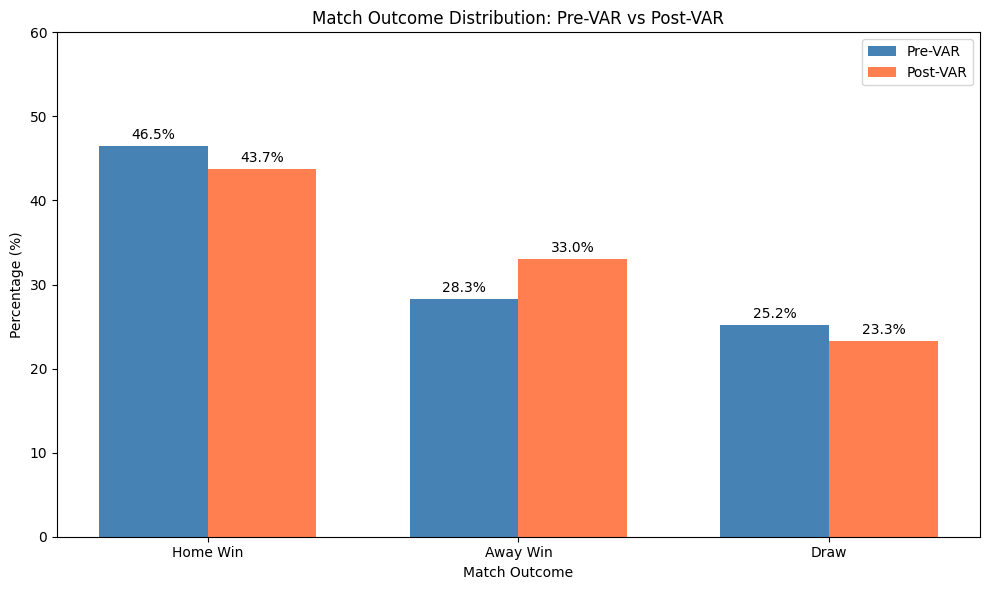

Chart saved!


In [75]:
# Visualise the result distribution pre vs post VAR
import matplotlib.pyplot as plt
import numpy as np

categories = ['Home Win', 'Away Win', 'Draw']
pre_var = [46.5, 28.3, 25.2]
post_var = [43.7, 33.0, 23.3]

x = np.arange(len(categories))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x - width/2, pre_var, width, label='Pre-VAR', color='steelblue')
bars2 = ax.bar(x + width/2, post_var, width, label='Post-VAR', color='coral')

ax.set_xlabel('Match Outcome')
ax.set_ylabel('Percentage (%)')
ax.set_title('Match Outcome Distribution: Pre-VAR vs Post-VAR')
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.legend()
ax.set_ylim(0, 60)

# Add value labels on bars
for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.5,
            f'{bar.get_height()}%', ha='center', va='bottom')
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.5,
            f'{bar.get_height()}%', ha='center', va='bottom')

plt.tight_layout()
plt.savefig('match_outcome_distribution.png', dpi=300)
plt.show()
print("Chart saved!")

In [76]:
# Compare key match variables pre vs post VAR
variables = ['FTH Goals', 'FTA Goals', 'H Yellow', 'A Yellow',
             'H Red', 'A Red', 'H Fouls', 'A Fouls']

pre_var = df[df['VAR']==0][variables].mean()
post_var = df[df['VAR']==1][variables].mean()

comparison = pd.DataFrame({
    'Pre-VAR Average': pre_var.round(3),
    'Post-VAR Average': post_var.round(3),
    'Change': (post_var - pre_var).round(3),
    'Change %': ((post_var - pre_var) / pre_var * 100).round(1)
})

print(comparison)

           Pre-VAR Average  Post-VAR Average  Change  Change %
FTH Goals            1.530             1.559   0.029       1.9
FTA Goals            1.137             1.325   0.189      16.6
H Yellow             1.394             1.697   0.302      21.7
A Yellow             1.760             1.873   0.113       6.4
H Red                0.064             0.055  -0.009     -13.9
A Red                0.093             0.062  -0.031     -33.8
H Fouls             11.486            10.678  -0.809      -7.0
A Fouls             12.058            10.835  -1.223     -10.1


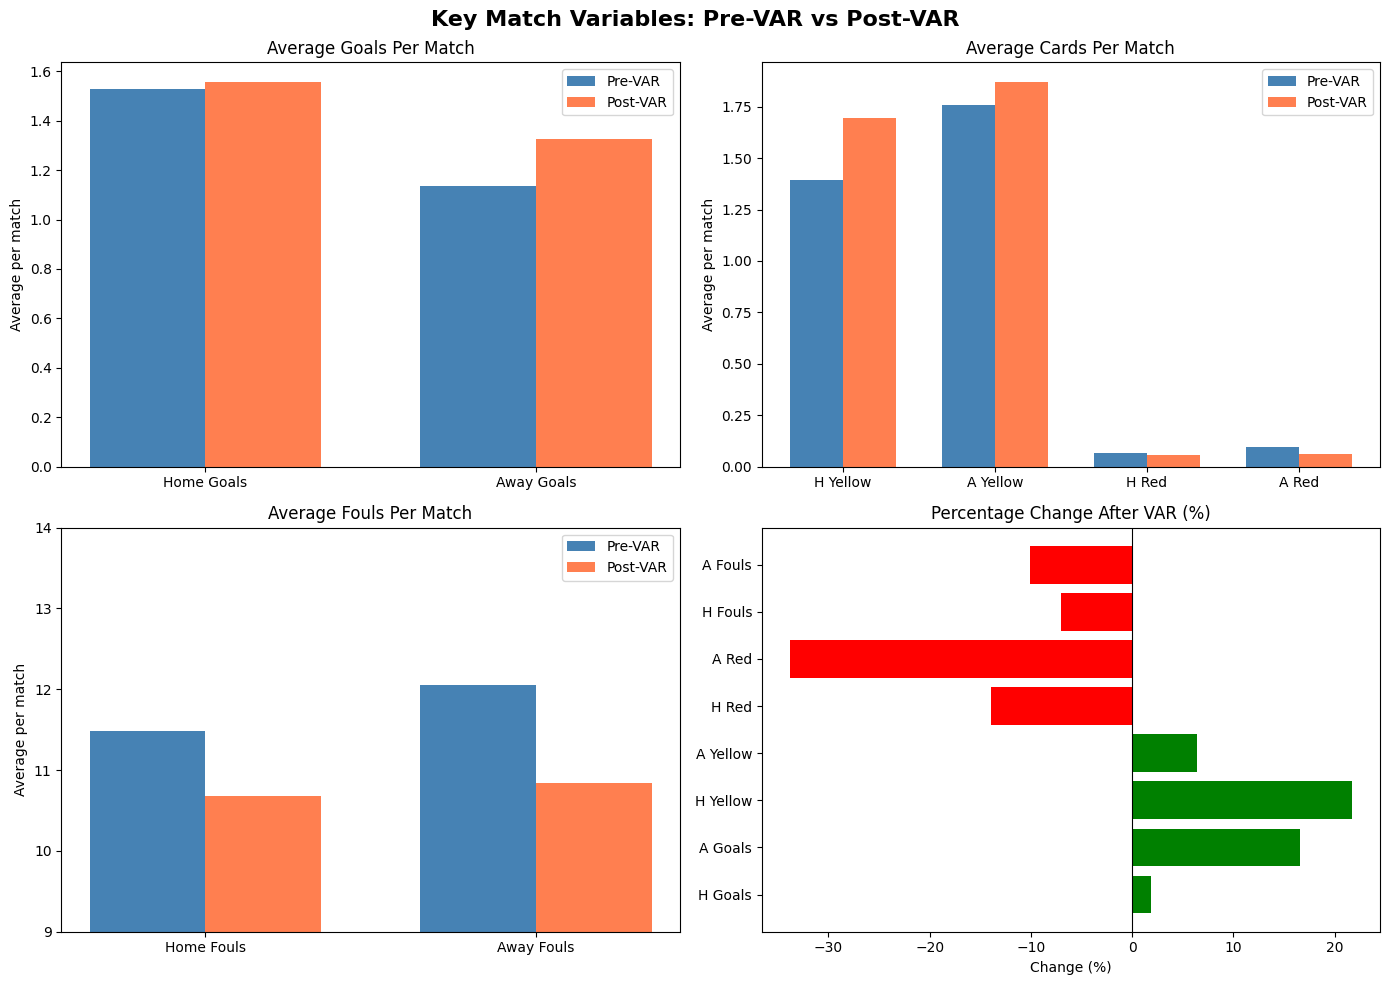

Chart saved!


In [77]:
# Visualise key variable changes
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Key Match Variables: Pre-VAR vs Post-VAR',
             fontsize=16, fontweight='bold')

# Goals
ax1 = axes[0, 0]
goals_pre = [1.530, 1.137]
goals_post = [1.559, 1.325]
x = np.arange(2)
ax1.bar(x - 0.175, goals_pre, 0.35, label='Pre-VAR', color='steelblue')
ax1.bar(x + 0.175, goals_post, 0.35, label='Post-VAR', color='coral')
ax1.set_title('Average Goals Per Match')
ax1.set_xticks(x)
ax1.set_xticklabels(['Home Goals', 'Away Goals'])
ax1.legend()
ax1.set_ylabel('Average per match')

# Cards
ax2 = axes[0, 1]
cards_pre = [1.394, 1.760, 0.064, 0.093]
cards_post = [1.697, 1.873, 0.055, 0.062]
x = np.arange(4)
ax2.bar(x - 0.175, cards_pre, 0.35, label='Pre-VAR', color='steelblue')
ax2.bar(x + 0.175, cards_post, 0.35, label='Post-VAR', color='coral')
ax2.set_title('Average Cards Per Match')
ax2.set_xticks(x)
ax2.set_xticklabels(['H Yellow', 'A Yellow', 'H Red', 'A Red'])
ax2.legend()
ax2.set_ylabel('Average per match')

# Fouls
ax3 = axes[1, 0]
fouls_pre = [11.486, 12.058]
fouls_post = [10.678, 10.835]
x = np.arange(2)
ax3.bar(x - 0.175, fouls_pre, 0.35, label='Pre-VAR', color='steelblue')
ax3.bar(x + 0.175, fouls_post, 0.35, label='Post-VAR', color='coral')
ax3.set_title('Average Fouls Per Match')
ax3.set_xticks(x)
ax3.set_xticklabels(['Home Fouls', 'Away Fouls'])
ax3.legend()
ax3.set_ylabel('Average per match')
ax3.set_ylim(9, 14)

# Change percentage
ax4 = axes[1, 1]
changes = [1.9, 16.6, 21.7, 6.4, -13.9, -33.8, -7.0, -10.1]
labels = ['H Goals', 'A Goals', 'H Yellow', 'A Yellow',
          'H Red', 'A Red', 'H Fouls', 'A Fouls']
colors = ['green' if x > 0 else 'red' for x in changes]
ax4.barh(labels, changes, color=colors)
ax4.axvline(x=0, color='black', linewidth=0.8)
ax4.set_title('Percentage Change After VAR (%)')
ax4.set_xlabel('Change (%)')

plt.tight_layout()
plt.savefig('key_variables_comparison.png', dpi=300)
plt.show()
print("Chart saved!")

In [78]:
# ============================================================
# CELL A — Combined significance testing (Welch's t-test + Mann-Whitney U)
# Replaces/extends the existing Cell 12
# ============================================================
from scipy import stats

print("Statistical Testing: Pre-VAR vs Post-VAR")
print("=" * 70)

variables = {
    'Away Goals': 'FTA Goals',
    'Home Goals': 'FTH Goals',
    'Home Yellow Cards': 'H Yellow',
    'Away Yellow Cards': 'A Yellow',
    'Home Red Cards': 'H Red',
    'Away Red Cards': 'A Red',
    'Home Fouls': 'H Fouls',
    'Away Fouls': 'A Fouls'
}

pre = df[df['VAR']==0]
post = df[df['VAR']==1]

results = []
for name, col in variables.items():
    u_stat, p_mw = stats.mannwhitneyu(pre[col], post[col], alternative='two-sided')
    t_stat, p_t = stats.ttest_ind(pre[col], post[col], equal_var=False)  # Welch's t-test
    results.append({
        'Variable': name,
        'Pre-VAR Mean': round(pre[col].mean(), 3),
        'Post-VAR Mean': round(post[col].mean(), 3),
        'Welch t P-value': round(p_t, 4),
        'Mann-Whitney U P-value': round(p_mw, 4),
        'Significant (both tests)': 'Yes' if (p_t < 0.05 and p_mw < 0.05) else 'No'
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))


# ============================================================
# CELL B — Negative Binomial GLM (VAR as predictor) for count variables
# New cell, insert after Cell A
# ============================================================
import statsmodels.formula.api as smf
import warnings
warnings.filterwarnings('ignore')

print("Negative Binomial GLM: VAR as predictor")
print("=" * 70)

glm_results = []
for name, col in variables.items():
    formula = f'Q("{col}") ~ VAR'
    model = smf.negativebinomial(formula=formula, data=df)
    fit = model.fit(disp=0)
    coef = fit.params['VAR']
    pval = fit.pvalues['VAR']
    irr = np.exp(coef)  # incidence rate ratio: exp(coefficient)
    glm_results.append({
        'Variable': name,
        'VAR Coefficient': round(coef, 4),
        'Incidence Rate Ratio': round(irr, 3),
        'P-Value': round(pval, 4),
        'Significant': 'Yes' if pval < 0.05 else 'No'
    })

glm_df = pd.DataFrame(glm_results)
print(glm_df.to_string(index=False))
print("\nInterpretation: IRR > 1 means the rate increases post-VAR (e.g. IRR of 1.166")
print("for Away Goals means a 16.6% increase); IRR < 1 means a decrease.")


# ============================================================
# CELL C — Multinomial logistic regression for match outcome (H/A/D)
# New cell, insert after Cell B
# ============================================================
import statsmodels.api as sm

print("Multinomial Logistic Regression: Match Outcome ~ VAR")
print("=" * 70)

# Draw (D) set as the reference/baseline category
result_map = {'D': 0, 'H': 1, 'A': 2}
df['Result_Code'] = df['FT Result'].map(result_map)

X = sm.add_constant(df['VAR'])
y = df['Result_Code']

mnlogit_model = sm.MNLogit(y, X)
mnlogit_fit = mnlogit_model.fit(disp=0)
print(mnlogit_fit.summary())

print("\nOdds Ratios (relative to Draw baseline):")
odds_ratios = np.exp(mnlogit_fit.params)
odds_ratios.columns = ['Home Win vs Draw', 'Away Win vs Draw']
print(odds_ratios)

print("\nP-values:")
pvals = mnlogit_fit.pvalues
pvals.columns = ['Home Win vs Draw', 'Away Win vs Draw']
print(pvals)


Statistical Testing: Pre-VAR vs Post-VAR
         Variable  Pre-VAR Mean  Post-VAR Mean  Welch t P-value  Mann-Whitney U P-value Significant (both tests)
       Away Goals         1.137          1.325           0.0000                  0.0000                      Yes
       Home Goals         1.530          1.559           0.3772                  0.5166                       No
Home Yellow Cards         1.394          1.697           0.0000                  0.0000                      Yes
Away Yellow Cards         1.760          1.873           0.0005                  0.0005                      Yes
   Home Red Cards         0.064          0.055           0.1358                  0.1688                       No
   Away Red Cards         0.093          0.062           0.0000                  0.0000                      Yes
       Home Fouls        11.486         10.678           0.0000                  0.0000                      Yes
       Away Fouls        12.058         10.835         

In [79]:
# ============================================================
# ROBUSTNESS CHECK 3 (RQ1): Recent-seasons-only statistical testing
# Insert after Cell C (multinomial logistic regression) and before Cell 14
# Mirrors the "Recent-seasons-only split" logic already used for RQ2/RQ3
# (Cell 23), but applied to RQ1's statistical tests instead of the ML models.
# ============================================================
import warnings
warnings.filterwarnings('ignore')

# Same balanced window used in the ML robustness check
recent_pre_var_seasons = ['2014/15', '2015/16', '2016/17', '2017/18', '2018/19']
recent_post_var_seasons = ['2019/20', '2020/21', '2021/22', '2022/23', '2023/24']

df_recent = df[df['Season'].isin(recent_pre_var_seasons + recent_post_var_seasons)].copy()

print("ROBUSTNESS CHECK 3 (RQ1): RECENT-SEASONS-ONLY STATISTICAL TESTING")
print("=" * 70)
print("Recent-window matches:", len(df_recent))
print(df_recent['VAR'].value_counts())

pre_r = df_recent[df_recent['VAR'] == 0]
post_r = df_recent[df_recent['VAR'] == 1]

# --- Welch's t-test + Mann-Whitney U (recent window) ---
print("\nWelch's t-test + Mann-Whitney U-test (recent-seasons window)")
print("-" * 70)
results_recent = []
for name, col in variables.items():
    u_stat, p_mw = stats.mannwhitneyu(pre_r[col], post_r[col], alternative='two-sided')
    t_stat, p_t = stats.ttest_ind(pre_r[col], post_r[col], equal_var=False)
    results_recent.append({
        'Variable': name,
        'Pre-VAR Mean': round(pre_r[col].mean(), 3),
        'Post-VAR Mean': round(post_r[col].mean(), 3),
        'Welch t P-value': round(p_t, 4),
        'Mann-Whitney U P-value': round(p_mw, 4),
        'Significant (both tests)': 'Yes' if (p_t < 0.05 and p_mw < 0.05) else 'No'
    })
results_recent_df = pd.DataFrame(results_recent)
print(results_recent_df.to_string(index=False))

# --- Negative Binomial GLM (recent window) ---
print("\nNegative Binomial GLM: VAR as predictor (recent-seasons window)")
print("-" * 70)
glm_recent_results = []
for name, col in variables.items():
    formula = f'Q("{col}") ~ VAR'
    fit = smf.negativebinomial(formula=formula, data=df_recent).fit(disp=0)
    coef = fit.params['VAR']
    pval = fit.pvalues['VAR']
    irr = np.exp(coef)
    glm_recent_results.append({
        'Variable': name,
        'VAR Coefficient': round(coef, 4),
        'Incidence Rate Ratio': round(irr, 3),
        'P-Value': round(pval, 4),
        'Significant': 'Yes' if pval < 0.05 else 'No'
    })
glm_recent_df = pd.DataFrame(glm_recent_results)
print(glm_recent_df.to_string(index=False))

# --- Multinomial logistic regression (recent window) ---
print("\nMultinomial Logistic Regression: Match Outcome ~ VAR (recent-seasons window)")
print("-" * 70)
df_recent['Result_Code'] = df_recent['FT Result'].map({'D': 0, 'H': 1, 'A': 2})
X_recent = sm.add_constant(df_recent['VAR'])
y_recent = df_recent['Result_Code']
mnlogit_recent_fit = sm.MNLogit(y_recent, X_recent).fit(disp=0)

odds_ratios_recent = np.exp(mnlogit_recent_fit.params)
odds_ratios_recent.columns = ['Home Win vs Draw', 'Away Win vs Draw']
pvals_recent = mnlogit_recent_fit.pvalues
pvals_recent.columns = ['Home Win vs Draw', 'Away Win vs Draw']

print("Odds Ratios (relative to Draw baseline):")
print(odds_ratios_recent)
print("\nP-values:")
print(pvals_recent)

# --- Comparison summary: full-era vs recent-window significance ---
print("\n" + "=" * 70)
print("SUMMARY: Full-era vs Recent-window significance comparison")
print("=" * 70)
comparison_summary = pd.DataFrame({
    'Variable': results_df['Variable'],
    'Significant (full era, 2000-2024)': results_df['Significant (both tests)'],
    'Significant (recent window, 2014-2024)': results_recent_df['Significant (both tests)']
})
print(comparison_summary.to_string(index=False))

ROBUSTNESS CHECK 3 (RQ1): RECENT-SEASONS-ONLY STATISTICAL TESTING
Recent-window matches: 3800
VAR
1    1900
0    1900
Name: count, dtype: int64

Welch's t-test + Mann-Whitney U-test (recent-seasons window)
----------------------------------------------------------------------
         Variable  Pre-VAR Mean  Post-VAR Mean  Welch t P-value  Mann-Whitney U P-value Significant (both tests)
       Away Goals         1.181          1.310           0.0009                  0.0018                      Yes
       Home Goals         1.533          1.563           0.4762                  0.6848                       No
Home Yellow Cards         1.565          1.649           0.0386                  0.0514                       No
Away Yellow Cards         1.751          1.827           0.0661                  0.0782                       No
   Home Red Cards         0.056          0.055           0.8380                  0.8291                       No
   Away Red Cards         0.079          0.06

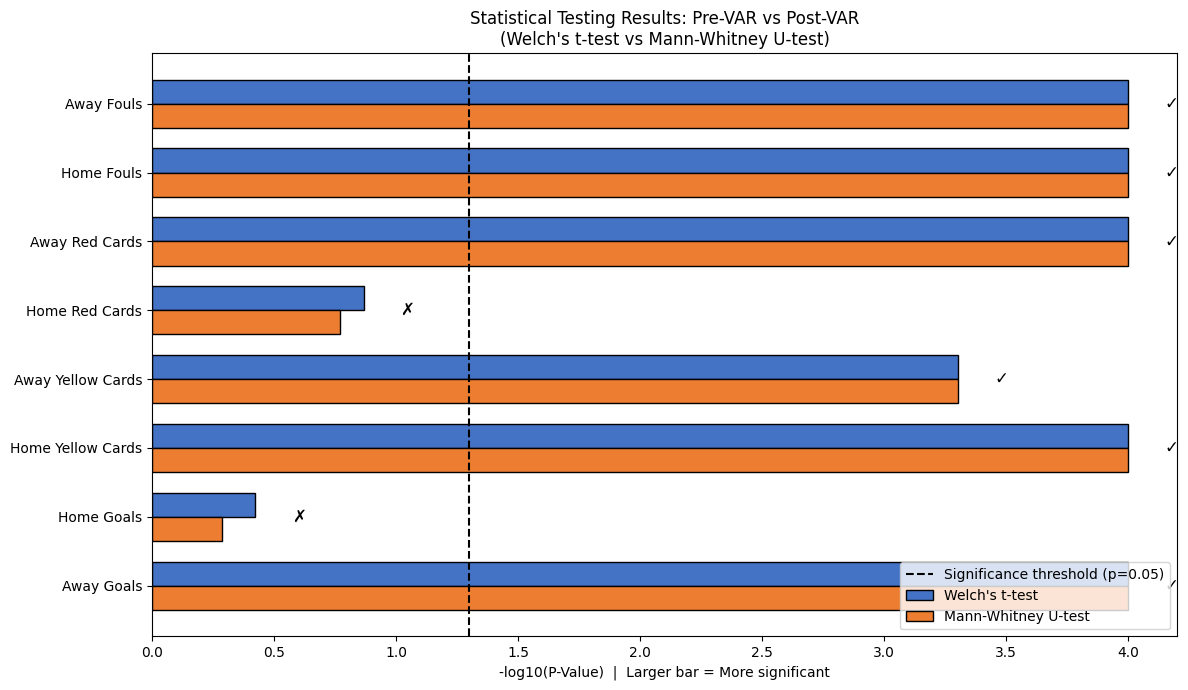

Chart saved!


In [80]:
# ============================================================
# REPLACEMENT for Cell 13 — dual-test comparison chart
# Works with the new results_df structure from Cell A
# (columns: Welch t P-value, Mann-Whitney U P-value, Significant (both tests))
# ============================================================
fig, ax = plt.subplots(figsize=(12, 7))

variables_list = list(results_df['Variable'])
welch_p = list(results_df['Welch t P-value'])
mw_p = list(results_df['Mann-Whitney U P-value'])
sig = list(results_df['Significant (both tests)'])

y_pos = np.arange(len(variables_list))
bar_height = 0.35

# Use -log10(p-value) so small p-values show as LARGE bars
welch_log = [-np.log10(max(p, 0.0001)) for p in welch_p]
mw_log = [-np.log10(max(p, 0.0001)) for p in mw_p]

ax.barh(y_pos + bar_height/2, welch_log, height=bar_height,
        label="Welch's t-test", color='#4472C4', edgecolor='black')
ax.barh(y_pos - bar_height/2, mw_log, height=bar_height,
        label='Mann-Whitney U-test', color='#ED7D31', edgecolor='black')

# Threshold line at -log10(0.05) = 1.301
ax.axvline(x=1.301, color='black', linestyle='--', linewidth=1.5,
           label='Significance threshold (p=0.05)')

ax.set_yticks(y_pos)
ax.set_yticklabels(variables_list)
ax.set_xlabel('-log10(P-Value)  |  Larger bar = More significant')
ax.set_title("Statistical Testing Results: Pre-VAR vs Post-VAR\n(Welch's t-test vs Mann-Whitney U-test)")
ax.legend(loc='lower right')

# Mark significant (both tests) variables
for i, s in enumerate(sig):
    mark = '\u2713' if s == 'Yes' else '\u2717'
    ax.text(max(welch_log[i], mw_log[i]) + 0.15, i, mark, va='center',
            fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('statistical_testing_results.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print("Chart saved!")

In [81]:
# Target variable encoding
target = 'FT Result'

# Encode target variable (H=0, D=1, A=2)
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['Result_Encoded'] = le.fit_transform(df[target])

print("Target encoding:")
print(dict(zip(le.classes_, le.transform(le.classes_))))

Target encoding:
{'A': np.int64(0), 'D': np.int64(1), 'H': np.int64(2)}


In [82]:
# Remove goals - they cause data leakage
# Use only performance features that don't reveal the result
features = ['H Shots', 'A Shots',
            'H SOT', 'A SOT',
            'H Fouls', 'A Fouls',
            'H Corners', 'A Corners',
            'H Yellow', 'A Yellow',
            'H Red', 'A Red']

# Prepare features and target again
X_train = df[df['VAR']==0][features]
y_train = df[df['VAR']==0]['Result_Encoded']

X_test = df[df['VAR']==1][features]
y_test = df[df['VAR']==1]['Result_Encoded']

print("Updated features:", features)
print("Total features:", len(features))
print("Training set size:", X_train.shape)
print("Testing set size:", X_test.shape)

Updated features: ['H Shots', 'A Shots', 'H SOT', 'A SOT', 'H Fouls', 'A Fouls', 'H Corners', 'A Corners', 'H Yellow', 'A Yellow', 'H Red', 'A Red']
Total features: 12
Training set size: (7220, 12)
Testing set size: (2109, 12)


In [83]:
# Retrain all 5 models with corrected features
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import cross_val_score
import warnings
warnings.filterwarnings('ignore')

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Define all 5 models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'XGBoost': XGBClassifier(random_state=42, eval_metric='mlogloss'),
    'MLP Neural Network': MLPClassifier(hidden_layer_sizes=(64, 32),
                                         max_iter=500, random_state=42)
}

# Train and evaluate each model
model_results = []

for name, model in models.items():
    print(f"Training {name}...")

    # Use scaled data for Logistic Regression and MLP
    if name in ['Logistic Regression', 'MLP Neural Network']:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
        cv_scores = cross_val_score(model, X_train_scaled, y_train, cv=5)
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        cv_scores = cross_val_score(model, X_train, y_train, cv=5)

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='weighted')
    cv_mean = cv_scores.mean()
    cv_std = cv_scores.std()

    model_results.append({
        'Model': name,
        'Test Accuracy': round(accuracy * 100, 2),
        'F1 Score': round(f1, 3),
        'CV Mean Accuracy': round(cv_mean * 100, 2),
        'CV Std': round(cv_std * 100, 2)
    })

    print(f"  Test Accuracy: {accuracy*100:.2f}%")
    print(f"  F1 Score: {f1:.3f}")
    print(f"  CV Accuracy: {cv_mean*100:.2f}% (+/- {cv_std*100:.2f}%)")
    print()

model_results_df = pd.DataFrame(model_results)
print("=" * 60)
print("FINAL MODEL COMPARISON")
print("=" * 60)
print(model_results_df.to_string(index=False))

Training Logistic Regression...
  Test Accuracy: 59.27%
  F1 Score: 0.541
  CV Accuracy: 55.83% (+/- 1.39%)

Training Decision Tree...
  Test Accuracy: 46.18%
  F1 Score: 0.468
  CV Accuracy: 42.34% (+/- 1.41%)

Training Random Forest...
  Test Accuracy: 58.42%
  F1 Score: 0.554
  CV Accuracy: 53.95% (+/- 1.43%)

Training XGBoost...
  Test Accuracy: 55.33%
  F1 Score: 0.540
  CV Accuracy: 52.70% (+/- 1.40%)

Training MLP Neural Network...
  Test Accuracy: 52.16%
  F1 Score: 0.508
  CV Accuracy: 49.10% (+/- 1.77%)

FINAL MODEL COMPARISON
              Model  Test Accuracy  F1 Score  CV Mean Accuracy  CV Std
Logistic Regression          59.27     0.541             55.83    1.39
      Decision Tree          46.18     0.468             42.34    1.41
      Random Forest          58.42     0.554             53.95    1.43
            XGBoost          55.33     0.540             52.70    1.40
 MLP Neural Network          52.16     0.508             49.10    1.77


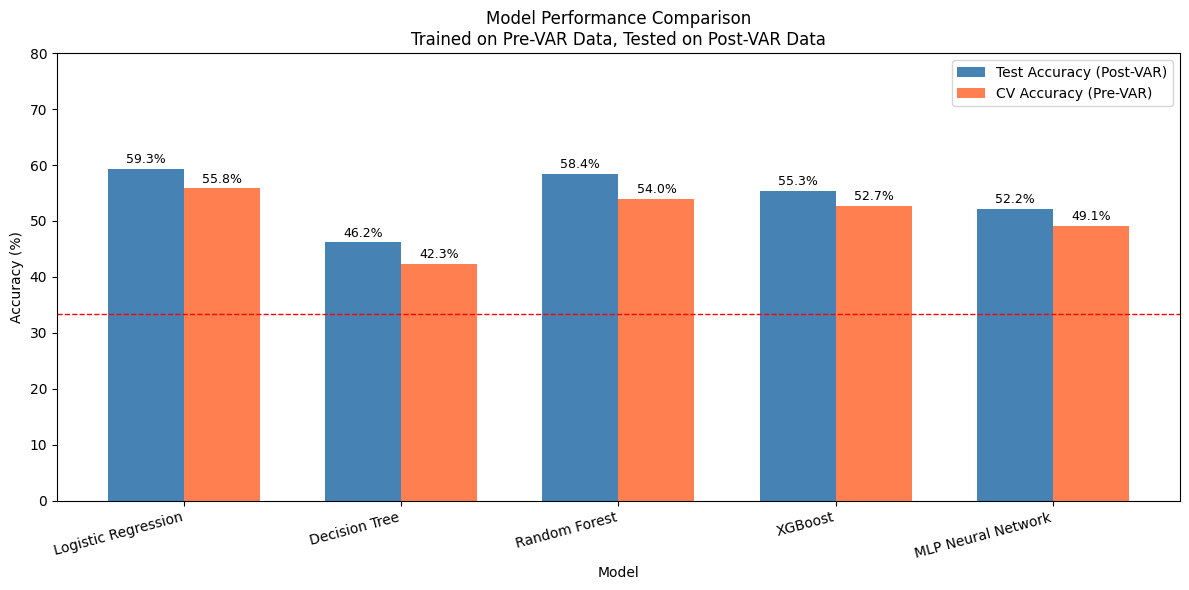

Chart saved!


In [84]:
# Visualise model comparison
fig, ax = plt.subplots(figsize=(12, 6))

model_names = model_results_df['Model']
test_acc = model_results_df['Test Accuracy']
cv_acc = model_results_df['CV Mean Accuracy']

x = np.arange(len(model_names))
width = 0.35

bars1 = ax.bar(x - width/2, test_acc, width,
               label='Test Accuracy (Post-VAR)', color='steelblue')
bars2 = ax.bar(x + width/2, cv_acc, width,
               label='CV Accuracy (Pre-VAR)', color='coral')

ax.set_xlabel('Model')
ax.set_ylabel('Accuracy (%)')
ax.set_title('Model Performance Comparison\nTrained on Pre-VAR Data, Tested on Post-VAR Data')
ax.set_xticks(x)
ax.set_xticklabels(model_names, rotation=15, ha='right')
ax.legend()
ax.set_ylim(0, 80)
ax.axhline(y=33.3, color='red', linestyle='--',
           linewidth=1, label='Random baseline (33.3%)')

# Add value labels on bars
for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.5,
            f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=9)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.5,
            f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=300,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Chart saved!")

In [85]:
import shap

# Use a simpler faster approach - use only 200 sample rows for SHAP
X_test_sample = X_test.sample(200, random_state=42)

# Train a smaller Random Forest just for SHAP
from sklearn.ensemble import RandomForestClassifier
rf_shap = RandomForestClassifier(n_estimators=20, random_state=42)
rf_shap.fit(X_train, y_train)

# Create SHAP explainer on smaller model and sample
explainer = shap.TreeExplainer(rf_shap)
shap_values = explainer.shap_values(X_test_sample)

print("SHAP values computed successfully")
print("Type:", type(shap_values))
if isinstance(shap_values, list):
    print("Number of classes:", len(shap_values))
    print("Shape per class:", shap_values[0].shape)
else:
    print("Shape:", shap_values.shape)

SHAP values computed successfully
Type: <class 'numpy.ndarray'>
Shape: (200, 12, 3)


  Feature  Mean |SHAP value|
    H SOT           0.082612
    A SOT           0.064566
  A Shots           0.030102
H Corners           0.022578
A Corners           0.020691
 H Yellow           0.019512
  A Fouls           0.018131
  H Shots           0.016937
  H Fouls           0.015363
 A Yellow           0.011910
    H Red           0.007812
    A Red           0.005453


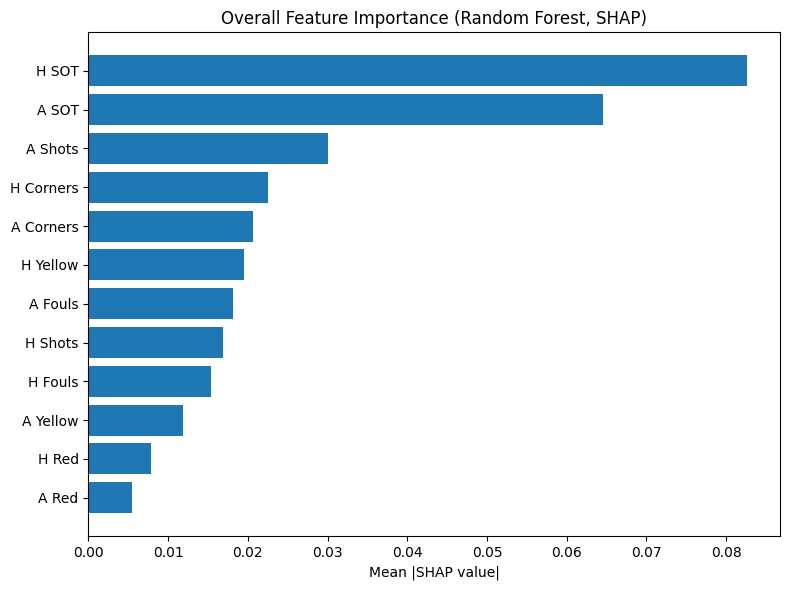

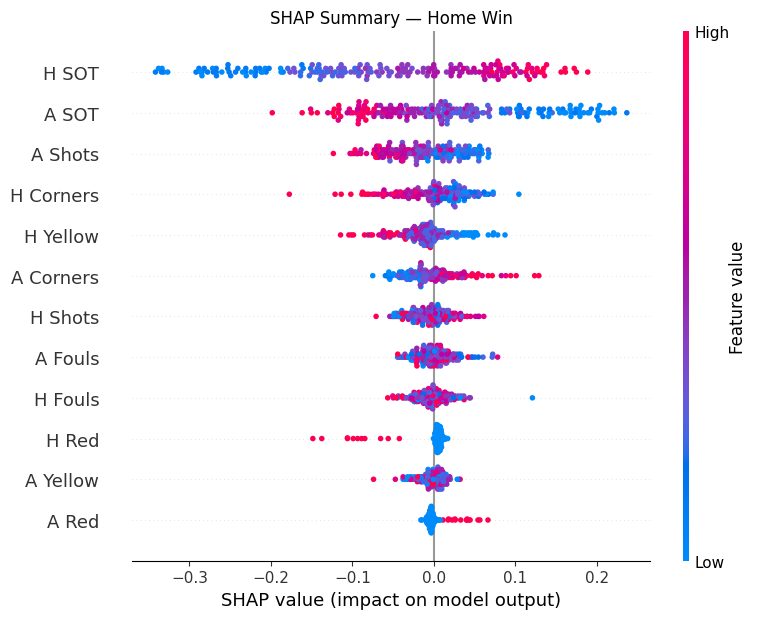

In [86]:
import matplotlib.pyplot as plt

# Class labels for reference
class_names = ['Away Win', 'Draw', 'Home Win']

# --- Option 1: Overall feature importance (mean |SHAP| across all classes) ---
# Average across the class dimension, then across samples
mean_abs_shap = np.abs(shap_values).mean(axis=(0, 2))  # shape: (12,)

importance_df = pd.DataFrame({
    'Feature': features,
    'Mean |SHAP value|': mean_abs_shap
}).sort_values('Mean |SHAP value|', ascending=False)

print(importance_df.to_string(index=False))

plt.figure(figsize=(8, 6))
plt.barh(importance_df['Feature'], importance_df['Mean |SHAP value|'])
plt.xlabel('Mean |SHAP value|')
plt.title('Overall Feature Importance (Random Forest, SHAP)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('shap_overall_importance.png', dpi=150)
plt.show()

# --- Option 2: Summary plot for one class at a time (e.g. Home Win) ---
shap.summary_plot(shap_values[:, :, 2], X_test_sample, feature_names=features,
                   show=False)
plt.title('SHAP Summary — Home Win')
plt.tight_layout()
plt.savefig('shap_home_win_summary.png', dpi=150)
plt.show()

In [87]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

# Set seeds for reproducibility
tf.random.set_seed(42)
np.random.seed(42)

# Scale features (already have scaler from earlier, but refit to be safe)
scaler_dl = StandardScaler()
X_train_dl = scaler_dl.fit_transform(X_train)
X_test_dl = scaler_dl.transform(X_test)

# Build a proper deep neural network
model_dl = keras.Sequential([
    layers.Input(shape=(X_train_dl.shape[1],)),

    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),

    layers.Dense(64, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),

    layers.Dense(32, activation='relu'),
    layers.Dropout(0.2),

    layers.Dense(3, activation='softmax')  # 3 classes: Away, Draw, Home
])

model_dl.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_dl.summary()

# Early stopping to prevent overfitting
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=15, restore_best_weights=True
)

# Train with a validation split (from training data only - test set stays untouched)
history = model_dl.fit(
    X_train_dl, y_train,
    validation_split=0.2,
    epochs=150,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

# Evaluate on the post-VAR test set
y_pred_probs = model_dl.predict(X_test_dl)
y_pred_dl = np.argmax(y_pred_probs, axis=1)

accuracy_dl = accuracy_score(y_test, y_pred_dl)
f1_dl = f1_score(y_test, y_pred_dl, average='weighted')

print(f"\nDeep Learning Model Results:")
print(f"Test Accuracy: {accuracy_dl*100:.2f}%")
print(f"F1 Score: {f1_dl:.3f}")

# Add to your results table (using model_results, the correct clean list)
model_results.append({
    'Model': 'Deep Neural Network',
    'Test Accuracy': round(accuracy_dl * 100, 2),
    'F1 Score': round(f1_dl, 3),
    'CV Mean Accuracy': None,  # k-fold CV not applied to DL training (see note)
    'CV Std': None
})

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 128)            │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,867 (50.26 KB)

 Trainable params: 12,483 (48.76 KB)

 Non-trainable params: 384 (1.50 KB)

Epoch 1/150
181/181 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.4732 - loss: 1.1857 - val_accuracy: 0.5319 - val_loss: 0.9950
Epoch 2/150
181/181 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5002 - loss: 1.0434 - val_accuracy: 0.5284 - val_loss: 0.9684
Epoch 3/150
181/181 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5204 - loss: 0.9950 - val_accuracy: 0.5471 - val_loss: 0.9608
Epoch 4/150
181/181 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.5272 - loss: 0.9726 - val_accuracy: 0.5499 - val_loss: 0.9564
Epoch 5/150
181/181 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5493 - loss: 0.9565 - val_accuracy: 0.5485 - val_loss: 0.9522
Epoch 6/150
181/181 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5493 - loss: 0.9503 - val_accuracy: 0.5526 - val_loss: 0.9440
Epoch 7/150
181/181 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.5594 - loss: 0.9387 - val_accuracy: 0.5568 - val_loss: 0.9411
Epoch 8/150
181/181 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5573 - loss: 0.9389 - val_accu

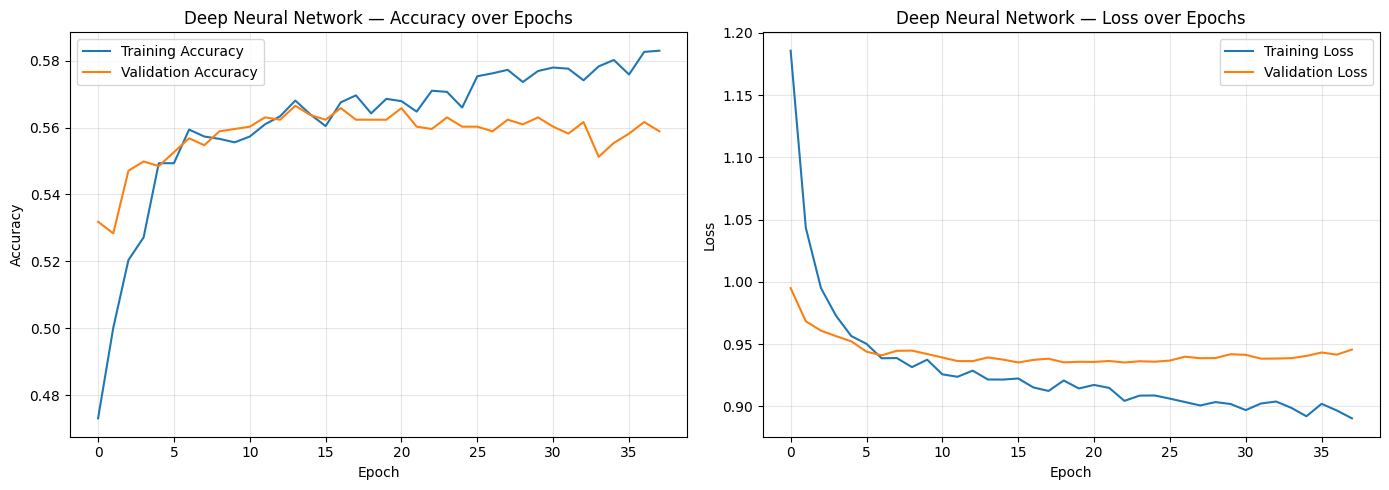

In [88]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy plot
axes[0].plot(history.history['accuracy'], label='Training Accuracy')
axes[0].plot(history.history['val_accuracy'], label='Validation Accuracy')
axes[0].set_title('Deep Neural Network — Accuracy over Epochs')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss plot
axes[1].plot(history.history['loss'], label='Training Loss')
axes[1].plot(history.history['val_loss'], label='Validation Loss')
axes[1].set_title('Deep Neural Network — Loss over Epochs')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('dnn_training_curves.png', dpi=150)
plt.show()

In [89]:
results_df_final = pd.DataFrame(model_results)

# Sort by Test Accuracy, descending
results_df_final = results_df_final.sort_values('Test Accuracy', ascending=False).reset_index(drop=True)

print("=" * 65)
print("FINAL MODEL COMPARISON — ALL 6 MODELS (leak-free features)")
print("=" * 65)
print(results_df_final.to_string(index=False))

# Save as CSV for easy inclusion in your dissertation
results_df_final.to_csv('final_model_comparison.csv', index=False)
print("\nSaved to final_model_comparison.csv")

FINAL MODEL COMPARISON — ALL 6 MODELS (leak-free features)
              Model  Test Accuracy  F1 Score  CV Mean Accuracy  CV Std
Logistic Regression          59.27     0.541             55.83    1.39
Deep Neural Network          58.94     0.544               NaN     NaN
      Random Forest          58.42     0.554             53.95    1.43
            XGBoost          55.33     0.540             52.70    1.40
 MLP Neural Network          52.16     0.508             49.10    1.77
      Decision Tree          46.18     0.468             42.34    1.41

Saved to final_model_comparison.csv


In [90]:
# Robustness Check 1: Recent-seasons-only split (balanced pre/post window)
recent_pre_var_seasons = ['2014/15', '2015/16', '2016/17', '2017/18', '2018/19']
recent_post_var_seasons = ['2019/20', '2020/21', '2021/22', '2022/23', '2023/24']

X_train_recent = df[df['Season'].isin(recent_pre_var_seasons)][features]
y_train_recent = df[df['Season'].isin(recent_pre_var_seasons)]['Result_Encoded']

X_test_recent = df[df['Season'].isin(recent_post_var_seasons)][features]
y_test_recent = df[df['Season'].isin(recent_post_var_seasons)]['Result_Encoded']

print("Recent-seasons training set:", X_train_recent.shape)
print("Recent-seasons testing set:", X_test_recent.shape)

# Scale
scaler_recent = StandardScaler()
X_train_recent_scaled = scaler_recent.fit_transform(X_train_recent)
X_test_recent_scaled = scaler_recent.transform(X_test_recent)

# Retrain all 5 classical models on this balanced window
recent_split_results = []

for name, model_class in [
    ('Logistic Regression', LogisticRegression(max_iter=1000, random_state=42)),
    ('Decision Tree', DecisionTreeClassifier(random_state=42)),
    ('Random Forest', RandomForestClassifier(n_estimators=100, random_state=42)),
    ('XGBoost', XGBClassifier(random_state=42, eval_metric='mlogloss')),
    ('MLP Neural Network', MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, random_state=42))
]:
    print(f"Training {name} (recent-seasons split)...")

    if name in ['Logistic Regression', 'MLP Neural Network']:
        model_class.fit(X_train_recent_scaled, y_train_recent)
        y_pred = model_class.predict(X_test_recent_scaled)
    else:
        model_class.fit(X_train_recent, y_train_recent)
        y_pred = model_class.predict(X_test_recent)

    accuracy = accuracy_score(y_test_recent, y_pred)
    f1 = f1_score(y_test_recent, y_pred, average='weighted')

    recent_split_results.append({
        'Model': name,
        'Test Accuracy': round(accuracy * 100, 2),
        'F1 Score': round(f1, 3)
    })
    print(f"  Test Accuracy: {accuracy*100:.2f}%  F1: {f1:.3f}")

recent_split_df = pd.DataFrame(recent_split_results)
print("\n" + "=" * 60)
print("ROBUSTNESS CHECK 1: RECENT-SEASONS-ONLY SPLIT")
print("=" * 60)
print(recent_split_df.to_string(index=False))

Recent-seasons training set: (1900, 12)
Recent-seasons testing set: (1900, 12)
Training Logistic Regression (recent-seasons split)...
  Test Accuracy: 61.84%  F1: 0.573
Training Decision Tree (recent-seasons split)...
  Test Accuracy: 46.74%  F1: 0.471
Training Random Forest (recent-seasons split)...
  Test Accuracy: 58.95%  F1: 0.555
Training XGBoost (recent-seasons split)...
  Test Accuracy: 56.84%  F1: 0.553
Training MLP Neural Network (recent-seasons split)...
  Test Accuracy: 50.47%  F1: 0.504

ROBUSTNESS CHECK 1: RECENT-SEASONS-ONLY SPLIT
              Model  Test Accuracy  F1 Score
Logistic Regression          61.84     0.573
      Decision Tree          46.74     0.471
      Random Forest          58.95     0.555
            XGBoost          56.84     0.553
 MLP Neural Network          50.47     0.504


In [91]:
# Robustness Check 2: COVID-adjusted sensitivity test (exclude 2020/21)
df_no_covid = df[df['COVID'] == 0]

X_train_covidadj = df_no_covid[df_no_covid['VAR']==0][features]
y_train_covidadj = df_no_covid[df_no_covid['VAR']==0]['Result_Encoded']

X_test_covidadj = df_no_covid[df_no_covid['VAR']==1][features]
y_test_covidadj = df_no_covid[df_no_covid['VAR']==1]['Result_Encoded']

print("COVID-excluded training set:", X_train_covidadj.shape)
print("COVID-excluded testing set:", X_test_covidadj.shape)

scaler_covidadj = StandardScaler()
X_train_covidadj_scaled = scaler_covidadj.fit_transform(X_train_covidadj)
X_test_covidadj_scaled = scaler_covidadj.transform(X_test_covidadj)

covid_adj_results = []

for name, model_class in [
    ('Logistic Regression', LogisticRegression(max_iter=1000, random_state=42)),
    ('Decision Tree', DecisionTreeClassifier(random_state=42)),
    ('Random Forest', RandomForestClassifier(n_estimators=100, random_state=42)),
    ('XGBoost', XGBClassifier(random_state=42, eval_metric='mlogloss')),
    ('MLP Neural Network', MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, random_state=42))
]:
    print(f"Training {name} (COVID-adjusted)...")

    if name in ['Logistic Regression', 'MLP Neural Network']:
        model_class.fit(X_train_covidadj_scaled, y_train_covidadj)
        y_pred = model_class.predict(X_test_covidadj_scaled)
    else:
        model_class.fit(X_train_covidadj, y_train_covidadj)
        y_pred = model_class.predict(X_test_covidadj)

    accuracy = accuracy_score(y_test_covidadj, y_pred)
    f1 = f1_score(y_test_covidadj, y_pred, average='weighted')

    covid_adj_results.append({
        'Model': name,
        'Test Accuracy': round(accuracy * 100, 2),
        'F1 Score': round(f1, 3)
    })
    print(f"  Test Accuracy: {accuracy*100:.2f}%  F1: {f1:.3f}")

covid_adj_df = pd.DataFrame(covid_adj_results)
print("\n" + "=" * 60)
print("ROBUSTNESS CHECK 2: COVID-ADJUSTED SENSITIVITY TEST")
print("=" * 60)
print(covid_adj_df.to_string(index=False))

COVID-excluded training set: (7220, 12)
COVID-excluded testing set: (1729, 12)
Training Logistic Regression (COVID-adjusted)...
  Test Accuracy: 59.22%  F1: 0.542
Training Decision Tree (COVID-adjusted)...
  Test Accuracy: 46.27%  F1: 0.469
Training Random Forest (COVID-adjusted)...
  Test Accuracy: 58.18%  F1: 0.552
Training XGBoost (COVID-adjusted)...
  Test Accuracy: 55.35%  F1: 0.540
Training MLP Neural Network (COVID-adjusted)...
  Test Accuracy: 51.94%  F1: 0.507

ROBUSTNESS CHECK 2: COVID-ADJUSTED SENSITIVITY TEST
              Model  Test Accuracy  F1 Score
Logistic Regression          59.22     0.542
      Decision Tree          46.27     0.469
      Random Forest          58.18     0.552
            XGBoost          55.35     0.540
 MLP Neural Network          51.94     0.507
